## Libraries

In [100]:
# Use this cell to regroup all your imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from scipy import stats
from tempfile import mkdtemp
from shutil import rmtree

from xgboost import XGBRegressor

from sklearn import set_config
set_config(display = 'diagram')

# Sklearn preprocessing
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.ensemble import AdaBoostRegressor, VotingRegressor, GradientBoostingRegressor, StackingRegressor, RandomForestRegressor
from sklearn.feature_selection import SelectPercentile, mutual_info_regression, VarianceThreshold, SelectFromModel
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.metrics import make_scorer, mean_squared_error, mean_squared_log_error
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

# 🏆 Kaggle Batch Competition

**Welcome to your first Kaggle competition!**

<img src='https://d32aokrjazspmn.cloudfront.net/materials/kaggle-batch-challenge.png' width=600>

Our goal is to submit predictions to the open [House Prices - Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques) competition online. 🏠

Since you have already worked with a dataset in the bootcamp, you are familiar with the topic. This time, you will build a baseline model using the provided guidelines. After creating the baseline, you are free to improve it and experiment with different approaches. The goal is to solve the problem using a complete machine learning pipeline.

### A few things to know about Kaggle:

- Kaggle ranks your submissions among all participants.
- Participants are removed from the general leaderboard after two months.
- You can submit up to 10 predictions per day.

### 🧹 Today is a great opportunity to practice keeping your notebook organized!

- Collapse all headings using the Command Palette (`Cmd + Shift + P`).
- Keep `idempotent` (Restart & Run All should never fail).
- Name your variables carefully and keep your code clean.

## Kaggle Setup

👉 Create a Kaggle account if you haven't already.

👉 Join the [House Prices Challenge](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques).

## Loading the Data

Follow the instructions below to download all the files you need from Kaggle into your current notebook folder.

- `train.csv` is your training dataset containing **X** and **y** (1460, 81).
- `test.csv` is your test dataset without the target variable (1459, 80). 🧚
- `sample_submission.csv` shows the required format for submitting your predictions.

ℹ️ You can find the detailed dataset description [here](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data). Refer to it throughout the competition!

Your goal is to predict the missing `y_pred` values in the test set, discover your `test_score`, and improve your ranking.

❓ Load your training dataset into a DataFrame named `data`. Create `X` and `y`, then inspect their shapes.

**💡 Tip:** If you inspect the CSV file, you will notice that it contains a column named `Id`. Make sure to use `index_col="Id"` when reading the CSV file into a DataFrame to avoid creating an additional ID column. 😉

In [101]:
data = pd.read_csv("data/train.csv", index_col="Id")

X = data.drop(columns="SalePrice")
y = data["SalePrice"]

print("Data shape:", data.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)

Data shape: (1460, 80)
X shape: (1460, 79)
y shape: (1460,)


# 🐣 1. BASELINE

## 1.1 Initial Feature Overview

We have 79 features, which is too many to handle individually in our first baseline pipeline! Let's process them based only on their data types.

❓ How many numerical and categorical features do we have?

In [102]:
numeric_features = X.select_dtypes(include=np.number).columns
categorical_features = X.select_dtypes(exclude=np.number).columns

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 36
Categorical features: 43


❓ Create a Series named `feat_categorical_nunique` containing the number of unique values for each categorical feature in our training dataset. How many unique categories are there in total?

In [103]:
feat_categorical_nunique = X[categorical_features].nunique()

print(feat_categorical_nunique)
print("Total unique categories:", feat_categorical_nunique.sum())

MSZoning          5
Street            2
Alley             2
LotShape          4
LandContour       4
Utilities         2
LotConfig         5
LandSlope         3
Neighborhood     25
Condition1        9
Condition2        8
BldgType          5
HouseStyle        8
RoofStyle         6
RoofMatl          8
Exterior1st      15
Exterior2nd      16
MasVnrType        3
ExterQual         4
ExterCond         5
Foundation        6
BsmtQual          4
BsmtCond          4
BsmtExposure      4
BsmtFinType1      6
BsmtFinType2      6
Heating           6
HeatingQC         5
CentralAir        2
Electrical        5
KitchenQual       4
Functional        7
FireplaceQu       5
GarageType        6
GarageFinish      3
GarageQual        5
GarageCond        5
PavedDrive        3
PoolQC            3
Fence             4
MiscFeature       4
SaleType          9
SaleCondition     6
dtype: int64
Total unique categories: 251


💡 If we apply `OneHotEncoder` to all categorical features, the feature matrix `X_preproc` will contain nearly 300 columns for only 1,400 observations (a high-dimensional problem). Ideally, we should aim to keep the number of features in our model below approximately 50. 🌈 [Read this practical rule](https://scikit-learn.org/stable/modules/feature_selection.html).

There are two main strategies we can use to reduce the number of categorical features after preprocessing:

1. **Drop:** Remove features that introduce too many categories. Their importance may require further statistical analysis.
2. **Ordinal Encoding:** Instead of one-hot encoding, assign numerical values to categorical variables. However, this creates an artificial ranking (1 > 2 > 3 > ...), which can be harmful if the categories do not have a natural order.

❓ Plot a histogram of the number of unique values per categorical feature. Do you notice any quick wins?

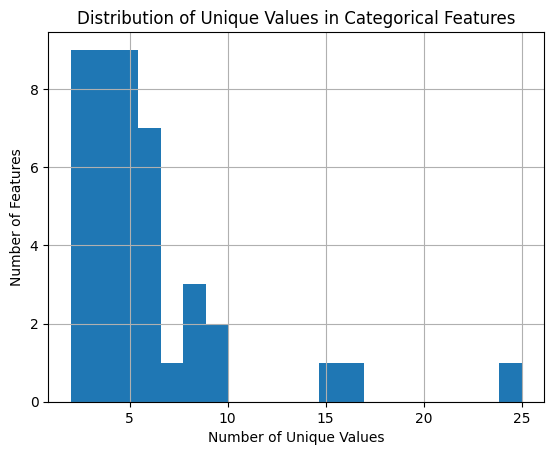

In [104]:
feat_categorical_nunique.hist(bins=20)

plt.xlabel("Number of Unique Values")
plt.ylabel("Number of Features")
plt.title("Distribution of Unique Values in Categorical Features")
plt.show()

💡 As a starting point, let's simply drop all features with 7 or more unique values and apply one-hot encoding to the remaining features. What do you think about this approach? We can save ordinal encoding and statistical feature selection for a later iteration of our pipeline.

❓ Store the names of the features to be one-hot encoded in a list called `feat_categorical_small`. How many features will be one-hot encoded?

In [105]:
feat_categorical_small = feat_categorical_nunique[
    feat_categorical_nunique < 7
].index.tolist()

print("Number of features for OneHotEncoding:", len(feat_categorical_small))
print(feat_categorical_small)

Number of features for OneHotEncoding: 34
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'BldgType', 'RoofStyle', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleCondition']


In [106]:
feat_categorical_large = feat_categorical_nunique[
    feat_categorical_nunique >= 7
].index.tolist()

print("Number of features for Ordinal Encoding:", len(feat_categorical_large))
print(feat_categorical_large)

Number of features for Ordinal Encoding: 9
['Neighborhood', 'Condition1', 'Condition2', 'HouseStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'Functional', 'SaleType']


🧪 Test your code below (and clear the cell once the test passes).

In [107]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'features_overview',
    n=len(feat_categorical_small)
)

result.write()
print(result.check())


============================= test session starts ==============================
platform darwin -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/bin/python
cachedir: .pytest_cache
rootdir: /Users/laraolgun/code/laraolgun74-creator/S17D2-S-kaggle-competition/tests
plugins: anyio-4.8.0, dash-4.4.1, typeguard-4.4.2
collecting ... collected 1 item

test_features_overview.py::TestFeaturesOverview::test_feat_categorical_small PASSED [100%]

============================== 1 passed in 0.01s ===============================


💯 You can commit your code:

git add tests/features_overview.pickle

git commit -m 'Completed features_overview step'

git push origin master



## 1.2 Baseline Pipeline

### a) Preprocessing

❓ Let's implement the basic preprocessing pipeline described below and save it as `preproc_baseline`.

**For categorical features:**
- Impute missing values using the most frequent value.
- Apply One-Hot Encoding to features with fewer than 7 unique values.
- Drop all remaining categorical features.

**For numerical features:**
- Impute missing values using the mean strategy.
- Apply Min-Max Scaling.

ℹ️ **Professional tip:** If you are not yet comfortable building longer syntax trees using `Pipeline` or `ColumnTransformer`, you can use Scikit-learn's shorter syntax with `make_pipeline` and `make_column_transformer`. These are also useful if you want to avoid manually specifying each step.

In [108]:
preproc_baseline = make_column_transformer(
    (
        make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(handle_unknown="ignore", drop="if_binary")
        ),
        feat_categorical_small
    ),
    (
        make_pipeline(
            SimpleImputer(strategy="mean"),
            MinMaxScaler()
        ),
        numeric_features
    ),
    remainder="drop"
)

❓ Check the shape of your preprocessed DataFrame and save it as `shape_preproc_baseline`.

In [109]:
shape_preproc_baseline = preproc_baseline.fit_transform(X).shape

🧪 Test your code below.

In [110]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'preproc_baseline',
    shape=shape_preproc_baseline
)

result.write()
print(result.check())


============================= test session starts ==============================
platform darwin -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/bin/python
cachedir: .pytest_cache
rootdir: /Users/laraolgun/code/laraolgun74-creator/S17D2-S-kaggle-competition/tests
plugins: anyio-4.8.0, dash-4.4.1, typeguard-4.4.2
collecting ... collected 1 item

test_preproc_baseline.py::TestPreprocBaseline::test_shape PASSED         [100%]

============================== 1 passed in 0.01s ===============================


💯 You can commit your code:

git add tests/preproc_baseline.pickle

git commit -m 'Completed preproc_baseline step'

git push origin master



### b) Add an Estimator

❓ Add a basic Decision Tree model to `preproc_baseline` and save the complete pipeline in a variable called `pipe_baseline`.

In [111]:
pipe_baseline = make_pipeline(
    preproc_baseline,
    DecisionTreeRegressor()
)

### c) Cross-Validation

❓ Read the [Kaggle competition evaluation rules](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/overview/evaluation). Which performance metric do you need? Is it readily available in Scikit-learn?

Unfortunately, no! We need to create a custom `sklearn.metrics.scorer` object before using cross-validation or Grid Search.

Here's how:

1. Use `make_scorer` to create a scorer called `rmsle` that can be passed as a value to the `scoring` keyword argument:

   `cross_val_score(pipe_baseline, X, y, cv=5, scoring=rmsle)`

2. Since we want to minimize the error, create another scorer called `rmsle_neg` with a negative score:

   `GridSearchCV(pipe_baseline, param_grid=..., cv=5, scoring=rmsle_neg)`

   `GridSearchCV` always tries to maximize the score, so using a negative error metric allows it to minimize the actual error.



RMSLE formula

$$\text{RMSLE}(y, \hat{y}) = \sqrt{\frac{1}{n_\text{samples}} \sum_{i=0}^{n_\text{samples} - 1} (\log_e (1 + y_i) - \log_e (1 + \hat{y}_i) )^2.}$$

In [112]:
from sklearn.metrics import root_mean_squared_log_error, make_scorer

rmsle = make_scorer(
    root_mean_squared_log_error,
    greater_is_better=False
)

❓ Evaluate your `pipe_baseline` using 5-fold cross-validation with this metric to get an initial idea of your baseline performance.

Save your average score as `score_baseline`.

In [113]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    pipe_baseline,
    X,
    y,
    cv=5,
    scoring=rmsle
)

score_baseline = -scores.mean()

print("Baseline RMSLE:", score_baseline)

/Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [12, 22] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [15, 20, 22] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [32] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5] during

Baseline RMSLE: 0.2116011420724621


/Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [9, 19, 30, 32] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


### d) Baseline Prediction

❓ Predict `y_pred_baseline` using the Kaggle `test.csv` dataset stored in the `data` folder.

In [114]:
X_test = pd.read_csv("https://d32aokrjazspmn.cloudfront.net/materials/houses_test_raw.csv")
X_test_ids = X_test['Id'] # Keep ids
X_test = X_test.drop(columns=['Id'])

# Predict y_pred_baseline
pipe_baseline.fit(X, y)
y_pred_baseline = pipe_baseline.predict(X_test)

❓ Finally, save your submission-ready CSV file as `submission_baseline.csv` in the `data` folder. Carefully inspect the required Kaggle submission format and validate it using the cell below (you do not need to submit this baseline to Kaggle yet).

In [115]:
results = pd.concat([X_test_ids, pd.Series(y_pred_baseline, name="SalePrice")], axis=1)
results.head(1)

,Id,SalePrice
0,1461,129000.0


In [116]:
# Export to Kaggle format submission in the `data` folder
results.to_csv("data/submission_baseline.csv", header=True, index=False)

🧪 Test your code.

In [117]:
from nbresult import ChallengeResult

tmp = pd.read_csv("data/submission_baseline.csv")

result = ChallengeResult(
    'submission_baseline',
    score_baseline = score_baseline,
    submission_shape = tmp.shape,
    submission_columns = list(tmp.columns),
    submission_dtypes = str(list(tmp.dtypes)),
)

result.write()
print(result.check())


============================= test session starts ==============================
platform darwin -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/bin/python
cachedir: .pytest_cache
rootdir: /Users/laraolgun/code/laraolgun74-creator/S17D2-S-kaggle-competition/tests
plugins: anyio-4.8.0, dash-4.4.1, typeguard-4.4.2
collecting ... collected 4 items

test_submission_baseline.py::TestSubmissionBaseline::test_score_baseline PASSED [ 25%]
test_submission_baseline.py::TestSubmissionBaseline::test_submission_columns PASSED [ 50%]
test_submission_baseline.py::TestSubmissionBaseline::test_submission_dtypes PASSED [ 75%]
test_submission_baseline.py::TestSubmissionBaseline::test_submission_shape PASSED [100%]

============================== 4 passed in 0.13s ===============================


💯 You can commit your code:

git add tests/submission_baseline.pickle

git commit -m 'Completed submission_baseline step'

git push origin master



# 🏋️ 2. ITERATIONS

🎉 Congratulations on building a complete baseline model with a full pipeline! Now you'll see how easy it can be to iterate and improve its performance. 🚀

Your goal now is to improve your predictions and submit them to Kaggle within the next 30 minutes. ⏱️

Below are some suggested improvements. Choose your battles and iteratively improve your pipeline in the way you find most appropriate!

**Models**

- Tree-based ensembles (definitely try these today); they are probably well suited for problems with many categorical features.
- Stacking!
- XGBoost!

**Preprocessing (come back here after getting your first ensemble model working)**

- Ordinal Encoding for categorical features with an implicit order in their values (e.g. "bad", "average", "good").
- Statistical Feature Selection to remove irrelevant features (prevents overfitting and reduces training time).
- Try predicting `log(SalePrice)` instead of `SalePrice`!

## 2.1 Preprocessing Iteration ♻️

⚠️ **Come back here after iterating on your models in Section 2.2!** ⚠️

➡️ If I'm not useful, drop me!

### a) Ordinal Encoding (~1s)

❓ Take a look at the following feature. Can we encode it numerically in a meaningful way?

**ExterQual:** Evaluates the quality of the exterior materials.

| Value | Description |
|---|---|
| Ex | Excellent |
| Gd | Good |
| TA | Average / Typical |
| Fa | Fair |
| Po | Poor |

💡 Fortunately, `OrdinalEncoder` and its `categories` argument allow us to do exactly that! Check the code below and make sure you understand how it works. 👇

In [118]:
# Define specific order for features
# Note: if you change this order, it will change the output for .transform()
feature_A_sorted_values = ['bad', 'average', 'good']
feature_B_sorted_values = ['dirty', 'clean', 'new']

encoder = OrdinalEncoder(
    categories=[
        feature_A_sorted_values,
        feature_B_sorted_values
    ],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

# Just some random training data
XX = [
    ['good', 'dirty'],
    ['bad', 'new'],
    ['average', 'clean'],
]

encoder.fit(XX)

encoder.transform([
        ['bad', "dirty"],
        ["average", "clean"],
        ['good', 'new'],
        ['bad', 'oops never seen this label before']
])

array([[ 0.,  0.],
       [ 1.,  1.],
       [ 2.,  2.],
       [ 0., -1.]])

❓ Now it's your turn: split your categorical features into the following groups:

- Some features (your choice) for ordinal encoding, stored in `preproc_ordinal`.
- The remaining features for one-hot encoding, stored in `preproc_nominal`.

💡 **Tips**

- You will need to hard-code the feature names and their ordered values. Keep the order consistent!
- Sorting the feature names alphabetically is a good practice to avoid mistakes.

In [119]:
for col in feat_categorical_large:
    print(f"\n{col}:")
    print(sorted(X[col].dropna().unique()))


Neighborhood:
['Blmngtn', 'Blueste', 'BrDale', 'BrkSide', 'ClearCr', 'CollgCr', 'Crawfor', 'Edwards', 'Gilbert', 'IDOTRR', 'MeadowV', 'Mitchel', 'NAmes', 'NPkVill', 'NWAmes', 'NoRidge', 'NridgHt', 'OldTown', 'SWISU', 'Sawyer', 'SawyerW', 'Somerst', 'StoneBr', 'Timber', 'Veenker']

Condition1:
['Artery', 'Feedr', 'Norm', 'PosA', 'PosN', 'RRAe', 'RRAn', 'RRNe', 'RRNn']

Condition2:
['Artery', 'Feedr', 'Norm', 'PosA', 'PosN', 'RRAe', 'RRAn', 'RRNn']

HouseStyle:
['1.5Fin', '1.5Unf', '1Story', '2.5Fin', '2.5Unf', '2Story', 'SFoyer', 'SLvl']

RoofMatl:
['ClyTile', 'CompShg', 'Membran', 'Metal', 'Roll', 'Tar&Grv', 'WdShake', 'WdShngl']

Exterior1st:
['AsbShng', 'AsphShn', 'BrkComm', 'BrkFace', 'CBlock', 'CemntBd', 'HdBoard', 'ImStucc', 'MetalSd', 'Plywood', 'Stone', 'Stucco', 'VinylSd', 'Wd Sdng', 'WdShing']

Exterior2nd:
['AsbShng', 'AsphShn', 'Brk Cmn', 'BrkFace', 'CBlock', 'CmentBd', 'HdBoard', 'ImStucc', 'MetalSd', 'Other', 'Plywood', 'Stone', 'Stucco', 'VinylSd', 'Wd Sdng', 'Wd Shng']


In [120]:
preproc_ordinal = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OrdinalEncoder(
        categories=[["Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"]],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )
)

### b) Statistical Feature Selection (~30 min)

Our goal is to remove the least informative features to reduce overfitting and shorten training time.

🔥 We will directly use Scikit-learn's feature selection transformers in our pipelines!

⚠️ To get started, we recommend trying only Option 1 today. Options 2 and 3 will be revisited during the recap session.

#### Option 1 (Recommended) – Univariate Feature Selection

*Based on the relationship with target `y`.*

- Feel free to add a `SelectPercentile` filter at the end of your preprocessing pipeline.
- This method filters out features that explain the target the least when considered individually.
- We recommend using `mutual_info_regression` as the statistical test passed to `SelectPercentile`.

💡 **What is mutual information? Click here!**

- Mutual information measures the statistical dependence between two random variables.
- Unlike correlation, it can capture non-linear relationships.
- It measures how much knowing one variable reduces uncertainty about another.
- Although correlation can be sufficient for linearly related features, mutual information can provide additional insights when relationships are monotonic but not necessarily linear.

In [121]:
preproc_selection_model = make_pipeline(
    preproc_baseline,
    SelectFromModel(
        RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    )
)

### Option 2 – Multivariate Feature Selection

*Based on combined relationships with the target `y`.*

💡 We want to remove features that do not help predict our target, even when considered together with other features.

**1. Permutation Importance**

We can use the `permutation_importance` metric together with an estimator.

Each feature is randomly shuffled, one at a time, and the model's performance is evaluated again. Features that cause the largest drop in performance are considered the most important.

A good way to perform this selection directly in a preprocessing pipeline is to use Scikit-learn's `SequentialFeatureSelector` transformer.

It iteratively selects the most useful features according to cross-validation scores. However, this process can be very time-consuming when the dataset contains many features.

**2. SelectFromModel**

Alternatively, we can use models that provide feature importance scores after fitting, which is generally faster.

For example:
- Tree-based models provide `feature_importances_`.
- Linear models with L1 regularization provide `coef_` values.

Scikit-learn provides the `SelectFromModel` transformer for this purpose.

In [122]:
preproc_selection_model = make_pipeline(
    SimpleImputer(strategy="median"),
    SelectFromModel(
        RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    )
)

### Option 3 – Unsupervised Feature Selection

*Based only on the properties of `X`, without considering the target `y`.*

❓ A quick win is to remove features with very low variance.

Think about it: a feature that contains only one unique value provides no useful information because it has zero variance.

Feel free to add a `VarianceThreshold` transformer at the end of your preprocessing pipeline!

In [123]:
from sklearn.feature_selection import SequentialFeatureSelector

In [124]:
preproc_sequential = make_pipeline(
    preproc_baseline,
    SequentialFeatureSelector(
        LinearRegression(),
        n_features_to_select=10,
        direction="forward",
        cv=3,
        n_jobs=-1
    )
)

In [125]:
preproc_variance = make_pipeline(
    preproc_baseline,
    VarianceThreshold(threshold=0.0)
)

❓ Additionally, we can examine correlations between our numerical features only.

- Use a **Pearson correlation matrix** to visually identify whether any numerical features are almost perfectly correlated with each other.
- Use **VIF (Variance Inflation Factor)** from `statsmodels` to identify features with high multicollinearity.

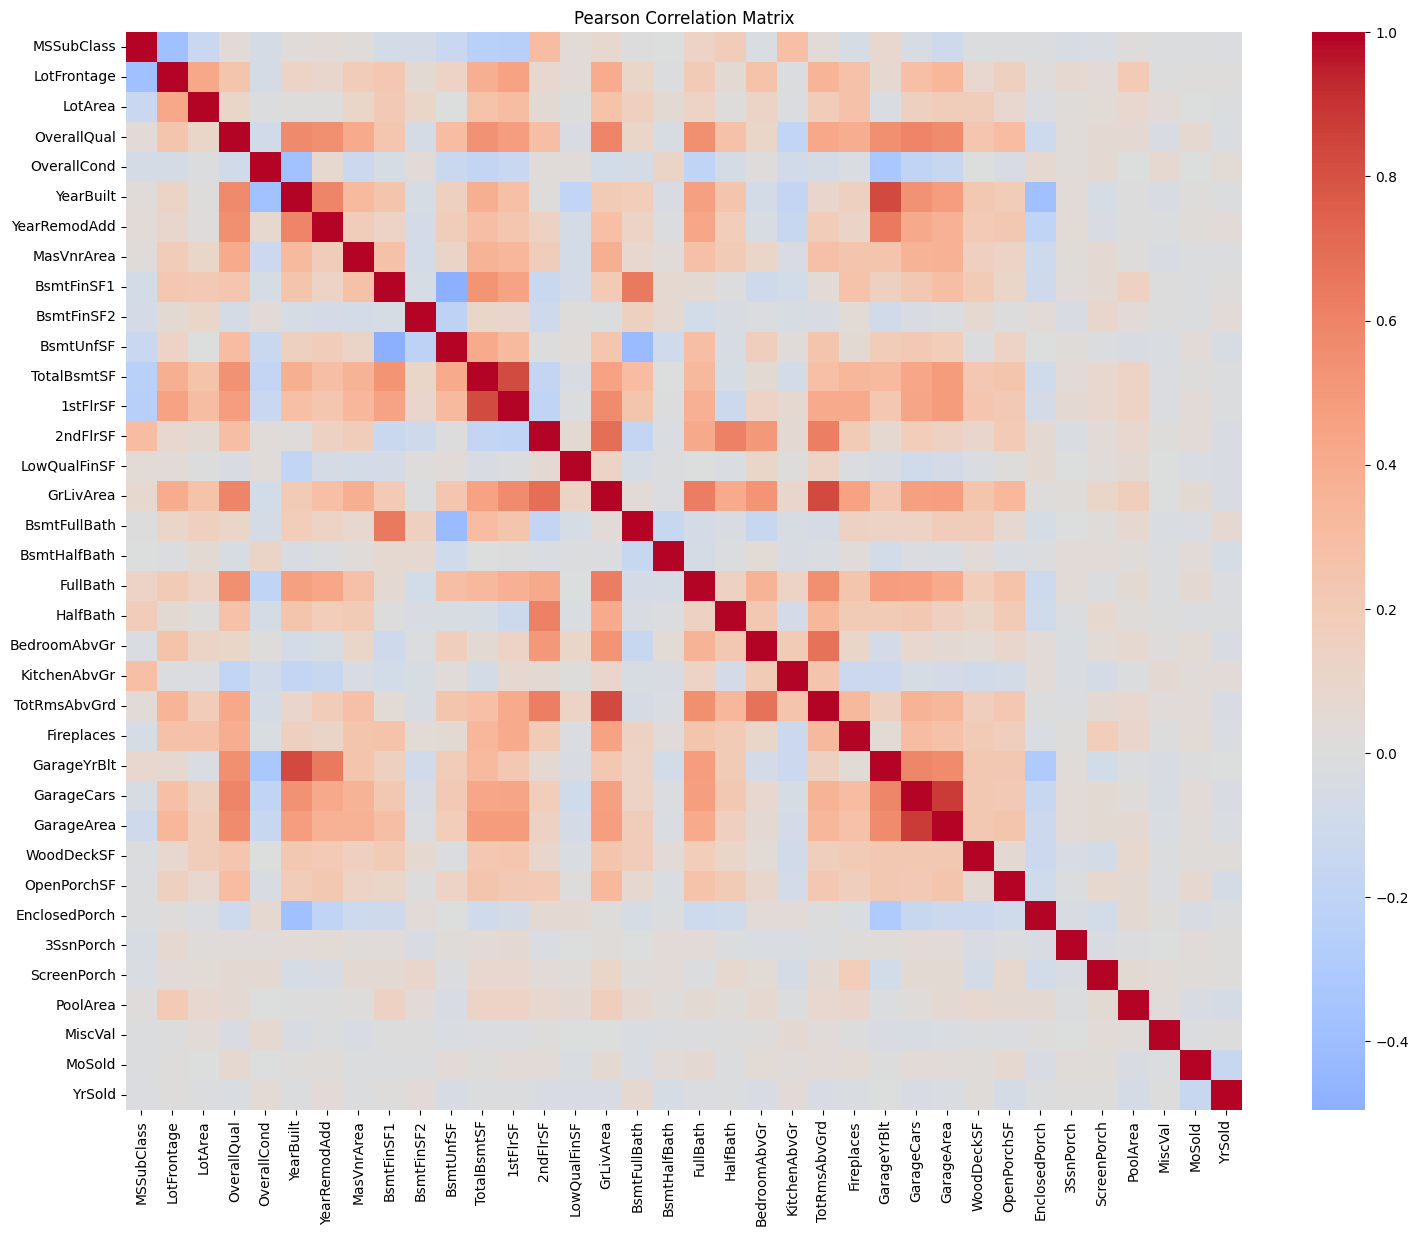

In [126]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = X[numeric_features].corr(method="pearson")

plt.figure(figsize=(18, 14))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0)
plt.title("Pearson Correlation Matrix")
plt.show()

In [127]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.impute import SimpleImputer

X_numeric = X[numeric_features]

X_numeric_imputed = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_numeric),
    columns=numeric_features
)

vif_data = pd.DataFrame({
    "Feature": X_numeric_imputed.columns,
    "VIF": [
        variance_inflation_factor(X_numeric_imputed.values, i)
        for i in range(X_numeric_imputed.shape[1])
    ]
})

vif_data = vif_data.sort_values("VIF", ascending=False)

display(vif_data)

/Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/lib/python3.12/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Feature,VIF
9,BsmtFinSF2,inf
8,BsmtFinSF1,inf
15,GrLivArea,inf
14,LowQualFinSF,inf
13,2ndFlrSF,inf
12,1stFlrSF,inf
11,TotalBsmtSF,inf
10,BsmtUnfSF,inf
35,YrSold,2.404984e+04
24,GarageYrBlt,2.251703e+04


❓ For ordinal features, we can use **Spearman rank correlation** instead of Pearson correlation to check whether their rankings are monotonically related, without assuming a linear relationship.

Feel free to create another correlation heatmap for these features!

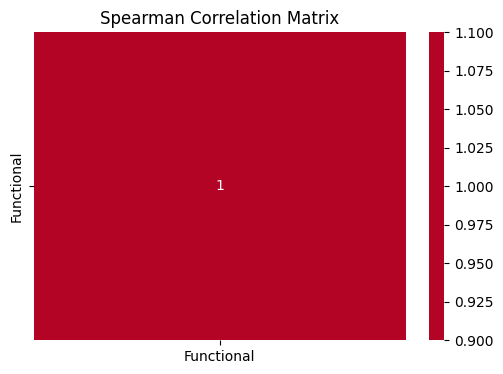

In [128]:
ordinal_features = ["Functional"]

ordinal_data = X[ordinal_features].copy()

ordinal_data["Functional"] = ordinal_data["Functional"].map({
    "Sev": 0,
    "Maj2": 1,
    "Maj1": 2,
    "Mod": 3,
    "Min2": 4,
    "Min1": 5,
    "Typ": 6
})

spearman_corr = ordinal_data.corr(method="spearman")

plt.figure(figsize=(6, 4))
sns.heatmap(spearman_corr, annot=True, cmap="coolwarm", center=0)
plt.title("Spearman Correlation Matrix")
plt.show()

❓ Feel free to create a custom **filter** in your pipeline that removes features exceeding a specified correlation threshold (based on Pearson or Spearman correlation). You will need to implement a custom transformer class for this purpose.

In [129]:
from sklearn.base import BaseEstimator, TransformerMixin

class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.90):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X)
        correlation_matrix = np.corrcoef(X, rowvar=False)
        correlation_matrix = np.nan_to_num(correlation_matrix)

        upper_triangle = np.triu(
            np.abs(correlation_matrix), k=1
        )

        self.to_drop_ = [
            column for column in range(upper_triangle.shape[1])
            if any(upper_triangle[:, column] > self.threshold)
        ]

        return self

    def transform(self, X):
        X = np.asarray(X)
        return np.delete(X, self.to_drop_, axis=1)

### c) Handle Cyclical Features

❓ Why do we transform time-based features into cyclical features?

💡 Cyclical encoding helps models understand that time-based values have a repeating pattern. For example, December and January are close to each other in a yearly cycle, even though their numerical values are far apart.

🔎 To learn more about why and how we apply this transformation, revisit the **Preprocessing Workflow** section in the **Prepare the Dataset** project.

In [130]:
X["MoSold_sin"] = np.sin(2 * np.pi * X["MoSold"] / 12)
X["MoSold_cos"] = np.cos(2 * np.pi * X["MoSold"] / 12)

X[["MoSold", "MoSold_sin", "MoSold_cos"]].head()

,MoSold,MoSold_sin,MoSold_cos
Id,,,
1,2,8.660254e-01,5.000000e-01
2,5,5.000000e-01,-8.660254e-01
3,9,-1.000000e+00,-1.836970e-16
4,2,8.660254e-01,5.000000e-01
5,12,-2.449294e-16,1.000000e+00


### d) Target Engineering (~15 min)

❓ We want to minimize RMSLE. Why not transform our target variable using the logarithm and predict its log-transformed values directly?

- Inspect the distribution of the target variable `y`.
- Normally distributed target variables are generally easier to model using linear or parametric models.
- Create `y_log` and define new performance metrics.
- Remember to convert your predictions back to the original scale at the end.

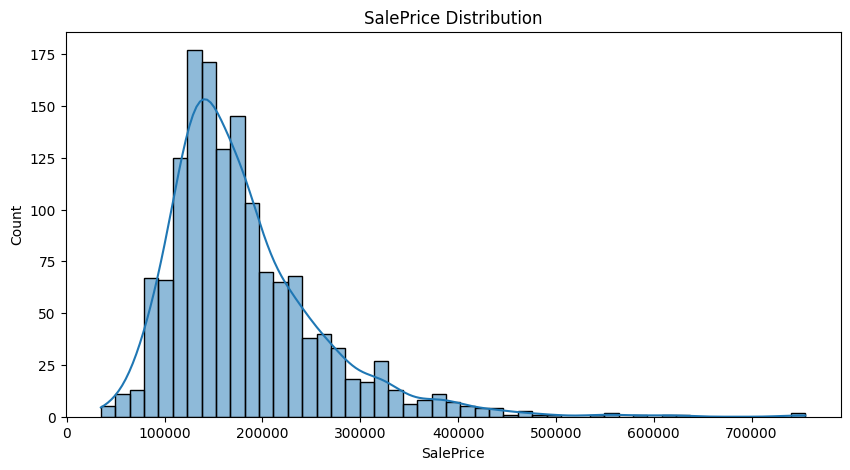

In [131]:
plt.figure(figsize=(10, 5))
sns.histplot(y, kde=True)
plt.title("SalePrice Distribution")
plt.xlabel("SalePrice")
plt.show()

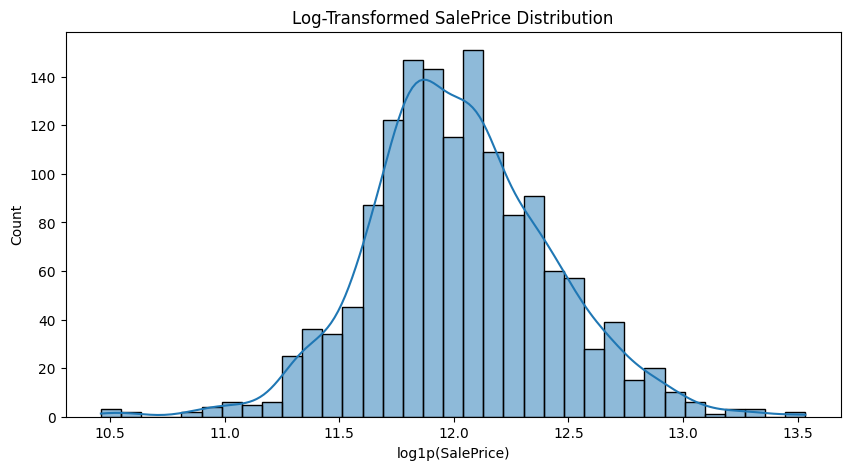

In [132]:
y_log = np.log1p(y)

plt.figure(figsize=(10, 5))
sns.histplot(y_log, kde=True)
plt.title("Log-Transformed SalePrice Distribution")
plt.xlabel("log1p(SalePrice)")
plt.show()

## 2.2 Model Iteration ♻️

### a) Final Version of the Preprocessing Pipeline

We recommend starting with a new definition of your preprocessing pipeline. Copy and paste your existing code from above.

This approach will allow you to update your preprocessing steps quickly when needed and experiment with multiple model types to find the best-performing model. You can also use GridSearchCV to optimize your models, although this may take some time.

Feel free to try one or more models that you have learned about in previous units or in this section.

👉 **Your goals:**

- Try at least one linear model.
- Try at least one of the tree-based models explored in this unit.
- Compare the cross-validation scores of your different models.
- Compare how long cross-validation takes for each model. 💡 Add the `%%time` magic command at the beginning of a notebook cell to measure its execution time.

In [133]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

models = {
    "Ridge": make_pipeline(
        preproc_baseline,
        Ridge(alpha=10)
    ),
    "Random Forest": make_pipeline(
        preproc_baseline,
        RandomForestRegressor(
            n_estimators=200,
            max_depth=None,
            random_state=42,
            n_jobs=-1
        )
    )
}

## 🥇 SUBMISSION

It's time to submit your predictions to Kaggle and discover your actual test score!

👉 Follow and complete the next steps to evaluate your model's performance.

In [134]:
X_test = pd.read_csv("https://d32aokrjazspmn.cloudfront.net/materials/houses_test_raw.csv")

X_test_ids = X_test['Id'] # Keep ids
X_test = X_test.drop(columns=['Id'])

If you applied the cyclical feature transformation in section 2.1, run the following cell to add the extra columns to `X_test` before passing it to your pipeline.

In [135]:
# If needed, add cyclical feature columns to X_test like we did to X
X_test["MoSold_sin"] = np.sin(2 * np.pi * X_test["MoSold"] / 12)
X_test["MoSold_cos"] = np.cos(2 * np.pi * X_test["MoSold"] / 12)

In [136]:
import time

model_results = []

for name, model in models.items():
    start_time = time.time()

    scores = cross_val_score(
        model,
        X,
        y_log,
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    elapsed_time = time.time() - start_time

    model_results.append({
        "Model": name,
        "Mean RMSLE": -scores.mean(),
        "Std": scores.std(),
        "Time (seconds)": elapsed_time
    })

results_df = pd.DataFrame(model_results)
display(results_df)

/Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [9, 19, 30, 32] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [12, 22] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [15, 20, 22] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/Users/laraolgun/.pyenv/versions/3.12.9/envs/workintech/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns

,Model,Mean RMSLE,Std,Time (seconds)
0,Ridge,0.148215,0.021051,3.638352
1,Random Forest,0.143184,0.009357,7.268129


👉 Use your best-performing model to make predictions and store the results in `predictions`.

In [137]:
best_model = models["Random Forest"]

best_model.fit(X, y_log)

predictions = np.expm1(best_model.predict(X_test))

predictions = np.maximum(predictions, 0)

print(predictions[:10])
print("Prediction count:", len(predictions))

[125532.2275107  152497.78584992 180711.53606784 179679.79171328
 197628.97772112 183158.60007577 165182.63483623 175754.68410785
 187495.30148826 121336.04515825]
Prediction count: 1459



👉 Run the following cells to prepare your predictions for submission to Kaggle.


In [138]:
# Create a DataFrame in the correct format
results = pd.concat([X_test_ids, pd.Series(predictions, name="SalePrice")], axis=1)
results

,Id,SalePrice
0,1461,125532.227511
1,1462,152497.785850
2,1463,180711.536068
3,1464,179679.791713
4,1465,197628.977721
...,...,...
1454,2915,83638.798228
1455,2916,83375.821313
1456,2917,153382.628753
1457,2918,112866.839283


In [139]:
# Export to Kaggle format submission
results.to_csv("submission_final.csv", header=True, index=False)


👉 Go to Kaggle and submit your predictions. What is your test score? Compare it with the cross-validation scores you obtained.


## Kaggle Submission Results

- Best Model: Random Forest Regressor
- Cross-Validation RMSLE: 0.143184
- Kaggle Public Score: 0.14437
- Target Transformation: log1p(SalePrice)